# Упражнение 3.4

Наша цель состоит в том, чтобы переместить линию ближе к точке (x, y) = (5, 15), используя приемы, которые освоили в этой главе. Для следующих двух задач возьмите скорость обучения 0.01.

1. Примените абсолютный подход, чтобы передвинуть линию выше —
и она оказалась ближе к точке.
2. Примените квадратический подход, чтобы передвинуть линию выше —
и она оказалась ближе к точке.

In [50]:
from Chapter_03_Linear_Regression.utils import draw_line, plot_points

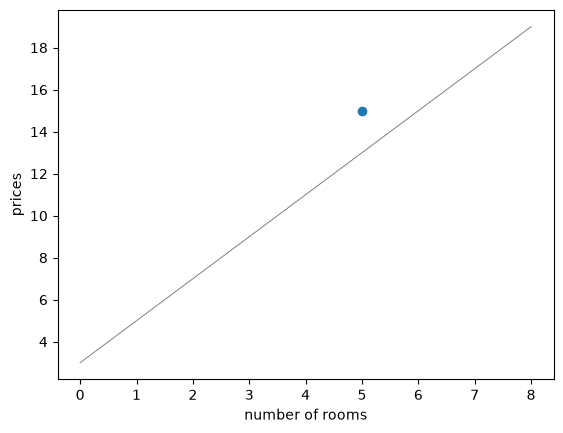

In [51]:
target_point = [5, 15]
# initial y_hat = 2 * x + 3
learning_rate = 0.01

plot_points(target_point[0], target_point[1])
initial_slope = 2
initial_y_intercept = 3
draw_line(initial_slope, initial_y_intercept)

In [52]:
def learn(x, y, initial_slp, initial_y_int, l_rate, learning_step_func):
    plot_points(x, y)
    slope, y_intercept = initial_slp, initial_y_int
    draw_line(slope, y_intercept)
    epoch_count = 0
    for i in range(100):
        epoch_count += 1
        current_slope, current_y_intercept = learning_step_func(x, y, slope, y_intercept, l_rate)
        slope, y_intercept = current_slope, current_y_intercept
        draw_line(slope, y_intercept)
        if abs(y - (x * current_slope + current_y_intercept)) < l_rate:
            break
    return slope, y_intercept, epoch_count

(2.3999999999999986, 3.0799999999999983, 100)

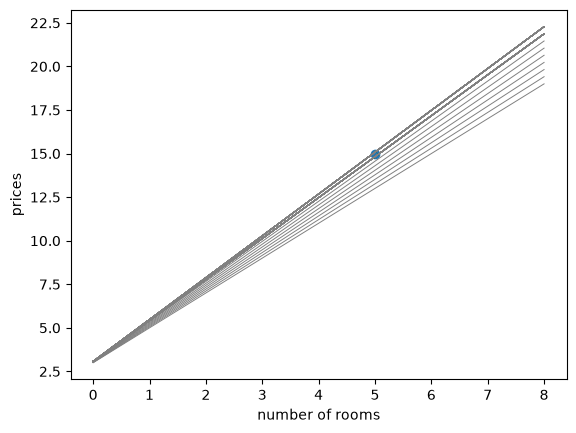

In [53]:
def absolute_trick(x, label, slope, y_intercept, l_rate):
    y_hat = slope * x + y_intercept
    if label > y_hat:
        new_slope = slope + l_rate * x
        new_y_intercept = y_intercept + learning_rate
    else:
        new_slope = slope - l_rate * x
        new_y_intercept = y_intercept - l_rate
    return new_slope, new_y_intercept

result_slope, result_y_intercept, epoch_count_fact = learn(target_point[0], target_point[1], initial_slope, initial_y_intercept, learning_rate, absolute_trick)
result_slope, result_y_intercept, epoch_count_fact

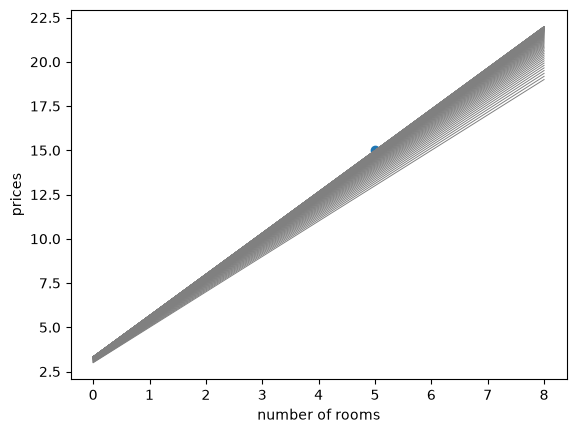

In [54]:
def square_trick(x, label, slope, y_intercept, l_rate):
    y_hat = slope * x + y_intercept
    delta = label - y_hat
    new_slope = slope + l_rate * delta
    new_y_intercept = y_intercept + learning_rate * delta

    return new_slope, new_y_intercept

result_slope, result_y_intercept, epoch_count_fact = learn(target_point[0], target_point[1], initial_slope, initial_y_intercept, learning_rate, square_trick)